In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Use the path matching the notebook's working directory:
path = Path("../data/processed/zev_county_year.csv")  # if cwd is notebooks/
# path = Path("data/processed/zev_county_year.csv")  # if cwd is the project root

df = pd.read_csv(path)

In [2]:
print(df.shape)

(1102, 9)


In [3]:
annual = (
    df.groupby("year", as_index=False)
      .agg(
          counties=("county", "nunique"),
          n_quarters=("n_quarters", "max"),
          zev_sales=("zev_total", "sum"),
      )
)

annual

,year,counties,n_quarters,zev_sales
0,2008,58,2,73
1,2009,58,4,502
2,2010,58,4,235
3,2011,58,4,5798
4,2012,58,4,16320
5,2013,58,4,37080
6,2014,58,4,55219
7,2015,58,4,54160
8,2016,58,4,68746
9,2017,58,4,89569


## Setup for charts

In [4]:
from matplotlib.ticker import FuncFormatter, PercentFormatter

joined = pd.read_csv(path.parent / "zev_census_county_year.csv")

# One accent hue; everything else stays in neutral ink so the data carries the color.
BLUE, MUTED = "#2a78d6", "#a3a29c"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2, "font.size": 10,
})
thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k" if v else "0")

## 1. Statewide ZEV sales over time

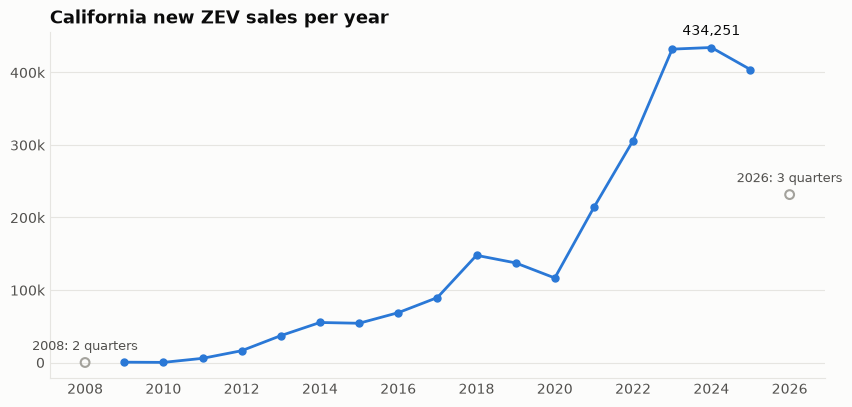

In [5]:
complete = annual[annual["n_quarters"] == 4]
partial = annual[annual["n_quarters"] < 4]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(complete["year"], complete["zev_sales"], color=BLUE, marker="o", markersize=5)
ax.scatter(partial["year"], partial["zev_sales"], s=40, facecolors="none",
           edgecolors=MUTED, linewidths=1.5, zorder=3)
for _, r in partial.iterrows():
    ax.annotate(f"{r.year}: {r.n_quarters} quarters", (r.year, r.zev_sales),
                xytext=(0, 9), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
peak = complete.loc[complete["zev_sales"].idxmax()]
ax.annotate(f"{peak.zev_sales:,.0f}", (peak.year, peak.zev_sales),
            xytext=(0, 9), textcoords="offset points", ha="center", color=INK)

ax.set_title("California new ZEV sales per year")
ax.yaxis.set_major_formatter(thousands)
ax.set_xticks(range(2008, 2027, 2))
ax.grid(axis="x", visible=False)
plt.show()

**Takeaway:** Sales grew about 75× from 2011 to a plateau of roughly 433k in 2023–24, then fell 7% in 2025 to 404k; growth has stalled rather than just slowed.

## 2. ZEV share by county: top and bottom 10

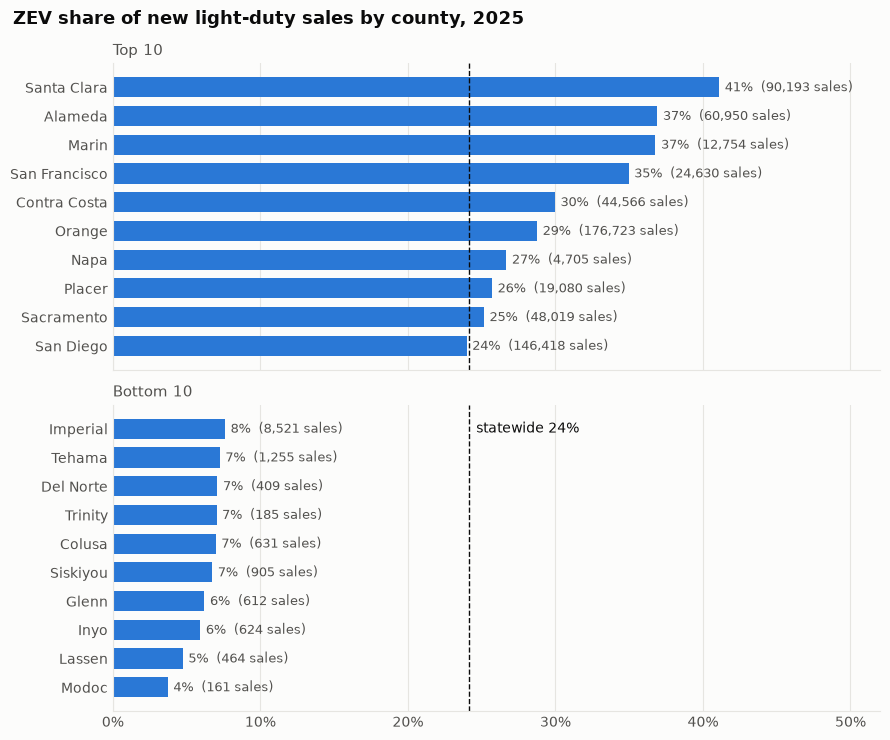

In [6]:
SHARE_YEAR = 2025  # latest full year of sales
sh = joined[joined["year"] == SHARE_YEAR].sort_values("zev_share", ascending=False)
state_share = sh["zev_total"].sum() / sh["ldv_total"].sum()
groups = [("Top 10", sh.head(10)), ("Bottom 10", sh.tail(10))]

fig, axes = plt.subplots(2, 1, figsize=(9, 7.5), sharex=True)
for ax, (label, part) in zip(axes, groups):
    part = part.iloc[::-1]  # largest at the top of each panel
    ax.barh(part["county"], part["zev_share"], color=BLUE, height=0.7)
    for i, r in enumerate(part.itertuples()):
        ax.annotate(f"{r.zev_share:.0%}  ({r.ldv_total:,} sales)", (r.zev_share, i), xytext=(4, 0),
                    textcoords="offset points", va="center", color=INK_2, fontsize=9)
    ax.axvline(state_share, color=INK, linewidth=1, linestyle="--")
    ax.set_title(label, fontsize=11, color=INK_2, fontweight="normal")
    ax.grid(axis="y", visible=False)
axes[1].annotate(f"statewide {state_share:.0%}", (state_share, 9), xytext=(5, 0),
                 textcoords="offset points", va="center", color=INK)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set_xlim(0, 0.52)
fig.suptitle(f"ZEV share of new light-duty sales by county, {SHARE_YEAR}", x=0.02, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

**Takeaway:** Santa Clara (41%) and Alameda and Marin (37%) lead against 24% statewide, while all of the bottom 10 are rural counties under 8%. Most of those sell only a few hundred new cars a year, so their shares move a lot from year to year.

## 3. ZEV share vs median income

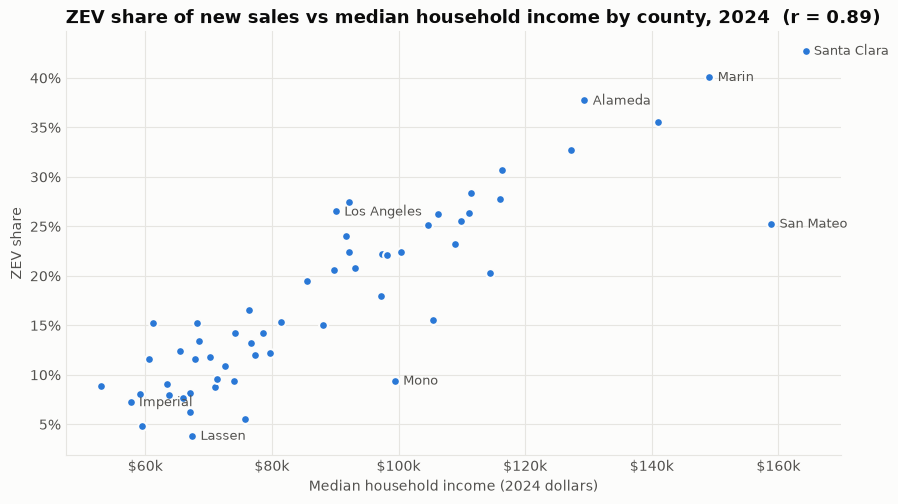

In [7]:
INC_YEAR = 2024  # latest year with ACS income
sc = joined[joined["year"] == INC_YEAR]
r = sc["zev_share"].corr(sc["median_income"])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(sc["median_income"], sc["zev_share"], s=40, color=BLUE,
           edgecolors="#fcfcfb", linewidths=1.5, zorder=3)
for name in ["Santa Clara", "Marin", "San Mateo", "Alameda", "Los Angeles", "Mono", "Lassen", "Imperial"]:
    p = sc[sc["county"] == name].iloc[0]
    ax.annotate(name, (p.median_income, p.zev_share), xytext=(6, -3),
                textcoords="offset points", color=INK_2, fontsize=9)

ax.set_title(f"ZEV share of new sales vs median household income by county, {INC_YEAR}  (r = {r:.2f})")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel(f"Median household income ({INC_YEAR} dollars)")
ax.set_ylabel("ZEV share")
plt.show()

**Takeaway:** Income goes a long way toward explaining the gaps between counties (r = 0.89): share climbs from roughly 5–15% in counties near $60k to 35–43% above $140k. San Mateo (25% at $159k) and Mono (9% at $99k) sit well below the trend.

## 4. Distribution of yearly growth rates

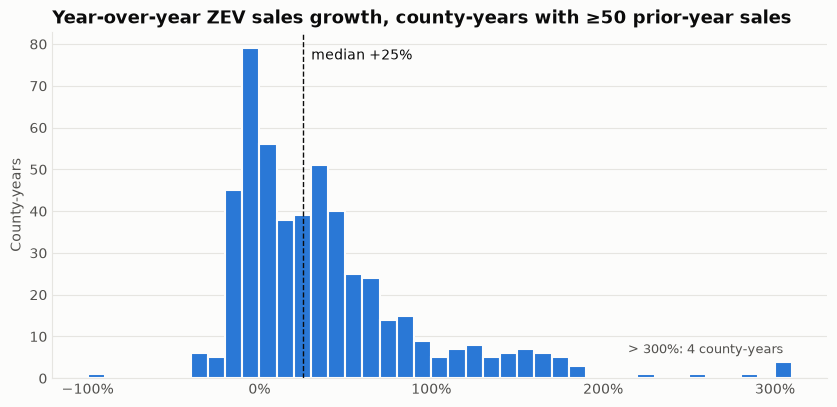

506 county-years; IQR -2% to +57%; 27% declined


In [8]:
MIN_PRIOR = 50  # tiny bases (e.g. 2 -> 9 ZEVs) produce meaningless percentages

g = joined[joined["n_quarters"] == 4].sort_values(["county", "year"]).copy()
g["prior"] = g.groupby("county")["zev_total"].shift()
g["prior_year"] = g.groupby("county")["year"].shift()
g = g[(g["prior_year"] == g["year"] - 1) & (g["prior"] >= MIN_PRIOR)]
g["growth"] = g["zev_total"] / g["prior"] - 1

CAP = 3.0  # fold the long right tail into one overflow bin
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(g["growth"].clip(upper=CAP), bins=[i / 10 for i in range(-10, 31, 1)] + [CAP + 0.1],
        color=BLUE, edgecolor="#fcfcfb", linewidth=1.5)
med = g["growth"].median()
ax.axvline(med, color=INK, linewidth=1, linestyle="--")
ax.annotate(f"median {med:+.0%}", (med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=INK)
ax.annotate(f"> {CAP:.0%}: {(g['growth'] > CAP).sum()} county-years", (CAP + 0.05, 0),
            xytext=(0, 18), textcoords="offset points", ha="right", color=INK_2, fontsize=9)

ax.set_title(f"Year-over-year ZEV sales growth, county-years with \u2265{MIN_PRIOR} prior-year sales")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("County-years")
ax.grid(axis="x", visible=False)
plt.show()

print(f"{len(g)} county-years; IQR {g['growth'].quantile(.25):+.0%} to "
      f"{g['growth'].quantile(.75):+.0%}; {(g['growth'] < 0).mean():.0%} declined")

**Takeaway:** The median county grows 25% a year, but the spread is wide: the middle half runs from −2% to +57%, and 27% of county-years shrank, so a single statewide growth rate won't fit every county.

## 5. ZEVs per 1,000 residents by county (2024)

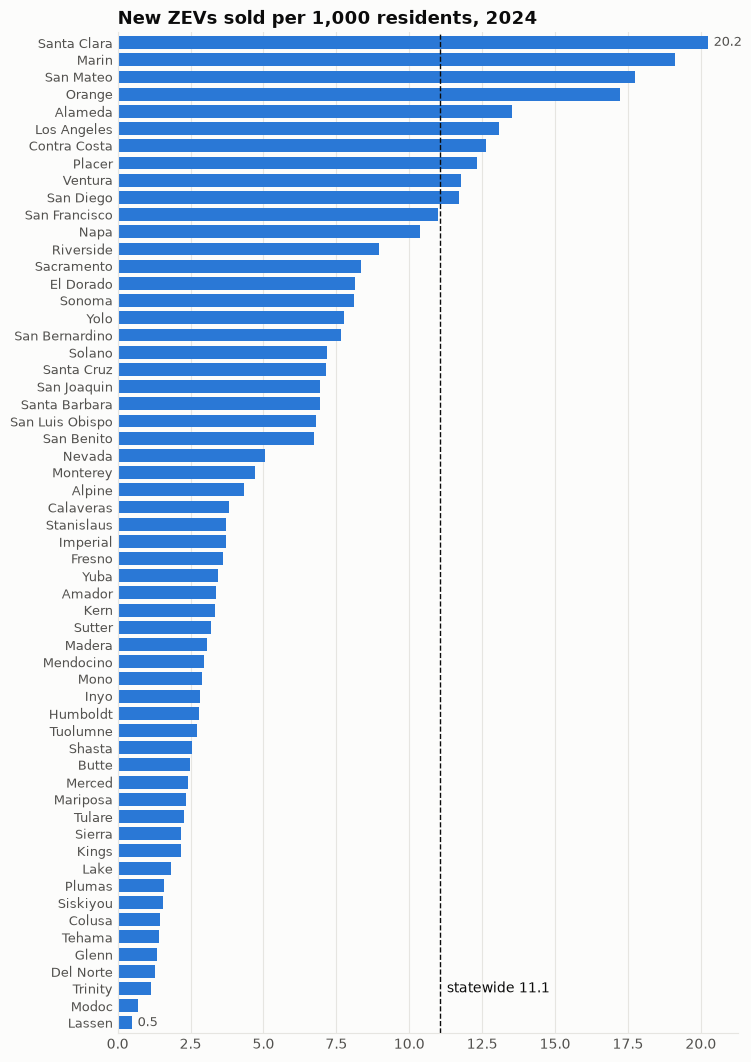

In [9]:
YEAR = 2024  # latest year with both full ZEV sales and ACS population
pc = joined[joined["year"] == YEAR].assign(
    per_1k=lambda x: x["zev_total"] / x["population"] * 1000
).sort_values("per_1k")
state = pc["zev_total"].sum() / pc["population"].sum() * 1000

fig, ax = plt.subplots(figsize=(8, 13))
ax.barh(pc["county"], pc["per_1k"], color=BLUE, height=0.75)
ax.axvline(state, color=INK, linewidth=1, linestyle="--")
ax.annotate(f"statewide {state:.1f}", (state, 2), xytext=(5, 0),
            textcoords="offset points", va="center", color=INK)
for i in [0, len(pc) - 1]:  # label only the extremes
    r = pc.iloc[i]
    ax.annotate(f"{r.per_1k:.1f}", (r.per_1k, i), xytext=(4, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)

ax.set_title(f"New ZEVs sold per 1,000 residents, {YEAR}")
ax.set_ylim(-0.6, len(pc) - 0.4)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=9)
plt.show()

**Takeaway:** Santa Clara, Marin, San Mateo and Orange lead at 17–20 per 1,000 residents, while the median county is at just 3.7 against a statewide 11.1: adoption is concentrated in a handful of large, high-income coastal counties.